## Basic Optimization

In this page we shall demosntrate how to use Scipy's optimization package.


Lets optimize $f(x) = \exp{(x-2)^2}$

In [7]:
!pip install scikit-optimize

In [8]:
import numpy as np
import matplotlib.pyplot as mp
import scipy as sp
from scipy import optimize
from scipy import fftpack
import skopt as opt

def f(y):
    return -np.exp(-(y-2)**2)

result = optimize.minimize_scalar(f)

print(result)

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: -1.0
       x: 1.9999999955459995
     nit: 6
    nfev: 10



### Using minimize function
We can also use Python's minimize or maximize function (with the ''key'' option) to optimize the function!

You can also pass more arguments.

Why to use the "optimize" function then?

min() only finds the smallest value from a given set, while scipy.optimize.minimize() searches for the optimal solution without requiring predefined values.

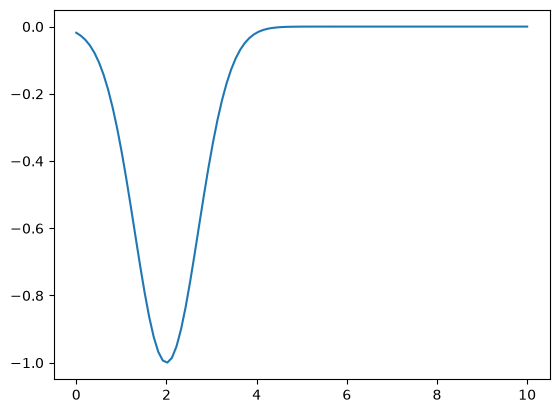

2.0202020202020203


In [9]:
y = np.linspace(0,10,100)
mp.plot(y,-np.exp(-(y-2)**2)); mp.show()
#print(max(y, key=lambda x: np.sinc(x-5)))

print(min(y, key=lambda x: -np.exp(-(x-2)**2)))

### Rosenbrock function

Now we optimize the infamous Rosenbrock function.

$f(x,y) = 0.5*(1-x)^2 + (y - x^2)^2$

In [10]:
def f(x):   # The rosenbrock function
    return .5*(1 - x[0])**2 + (x[1] - x[0]**2)**2
optimize.minimize(f, [0,-1], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 1.2743806081839638e-11
       x: [ 1.000e+00  1.000e+00]
     nit: 8
     jac: [-2.100e-07  2.518e-06]
    nfev: 48
    njev: 16

What happens if we change the seed to something very far from the solution point?

In [11]:
optimize.minimize(f, [200,-110], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 2.988484547652788e-10
       x: [ 1.000e+00  1.000e+00]
     nit: 19
     jac: [ 6.786e-06  8.505e-06]
    nfev: 158
    njev: 52

**Constrained Optimization**

In this you need to give the constraints as well.

For example: $f(x) = 2xy + 2x - x^2 - 2 y^2$.

Constraints are as follows:

$x^3−y = 0$

$y−1 \geq 0$

In [12]:
def func(x, sign=1.0):
    """ Objective function """
    return sign*(2*x[0]*x[1] + 2*x[0] - x[0]**2 - 2*x[1]**2)

cons = ({'type': 'eq',
          'fun' : lambda x: np.array([x[0]**3 - x[1]])},
        {'type': 'ineq',
          'fun' : lambda x: np.array([x[1] - 1])})

res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                method='SLSQP', options={'disp': True})
print(res.x)

Optimization terminated successfully    (Exit mode 0)
            Current function value: -1.999999999999997
            Iterations: 4
            Function evaluations: 13
            Gradient evaluations: 4
[1.99999994 0.99999995]


In [13]:
res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                constraints=cons, method='BFGS', options={'disp': True})

print(res.x)

Optimization terminated successfully.
         Current function value: -2.000000
         Iterations: 6
         Function evaluations: 21
         Gradient evaluations: 7
[2.00000009 1.00000005]


C:\Users\mikol\AppData\Local\Temp\ipykernel_7568\2128810766.py:1: RuntimeWarning: Method BFGS cannot handle constraints.
  res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),


## COMPRESSIVE SENSING

Now lets discuss about compressive sensing. Lets assume that we have some signal recorded (following Nyquist rate); lets call it $x$. Its size is $N$.

In the following signal we are using 500 samples and two sinusoids. You can note that one of them takes 10 samples per cycle; hence there are 50 cycles. So Nyquist will want us to have at least 100 samples in order to be able to know whats in the signal!

However if we look the signal through DCT then there are just two samples. Mark that we are using DCT and not FFT; because then we dont have to deal with complex numbers!



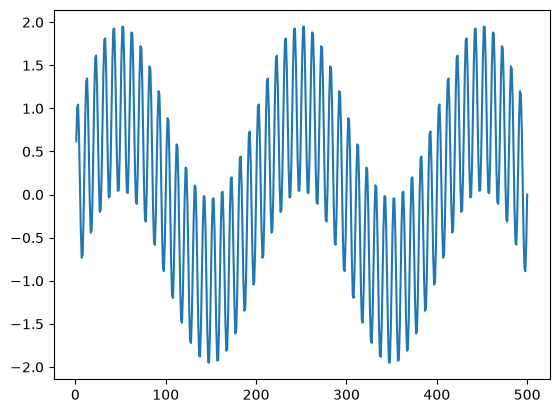

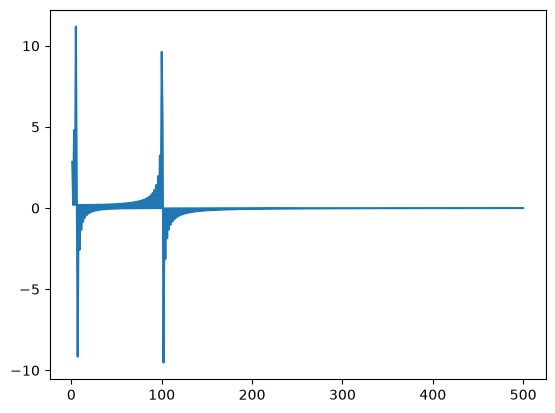

([<matplotlib.lines.Line2D at 0x1dc00de3750>], None)

In [14]:
n = np.linspace(1,500,500)

#two harmonics signal
xx = np.sin(2*np.pi*n/10) + np.sin(2*np.pi*n/200)  #+ np.sin(2*np.pi*n/50)
mp.plot(n,xx), mp.show()
mp.plot(n,fftpack.dct(xx, norm='ortho')), mp.show()

**Sparse Sampling** \\
Lets assume that we only consider $n$ of this ($n \ll N$).

For this lets define a sparsifying vector sp which has only $n$ 1's and rest zeros placed in random places.

So sparsed data $xp = xx*sp$.

The trick is that these $n$ samples are randomly taken.

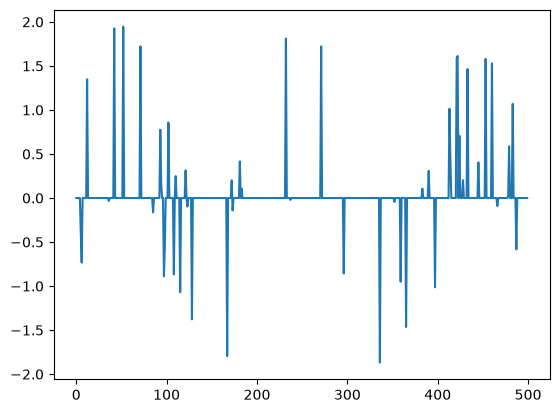

([<matplotlib.lines.Line2D at 0x1dc03e40e10>], None)

In [15]:
N = len(xx) #length of actual N
n = 50 #number of nonzero samples in our sparse signal
sp = np.array([1] * n + [0] * (N-n)) #n 1's and (N-n) 0's
np.random.shuffle(sp)

xp = xx*sp
mp.plot(xp), mp.show()

### Using Optimization
The trick of compressive sensing is that we try to use optimization in order to know the unknown from what is known!

So let us think what we know.

1- We know $xp$  the random-subNyquist-sampled signal and $sp$.

2- We know that the signal is sparse in DCT domain.

So lets try to look into the DCT domain. Lets assume that the DCT of the signal is $XX$. So IDCT of it should give us $xp$ back.

Lets define an optimization problem to do this.

What are the DCT samples that will give rise to a time domain signal which has the values of $xp$ at $sp$ time-indices. \\
We start with an intial estimate $XX$ which we will update in each iteration. \\
The cost function will be Euclidean distance between $xp$ and IDCT of $XX$.

         Current function value: 0.000001
         Iterations: 3
         Function evaluations: 39090
         Gradient evaluations: 78


m:\Mikolaj\ML4space\.venv\Lib\site-packages\scipy\optimize\_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


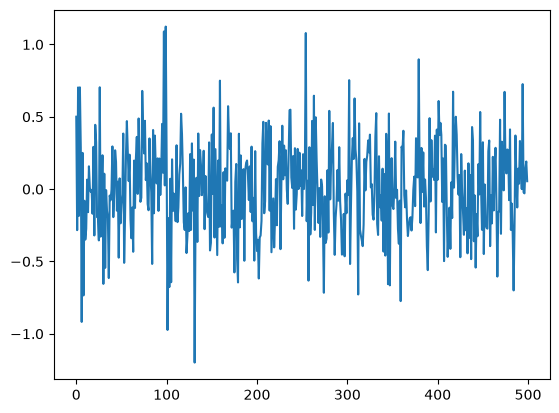

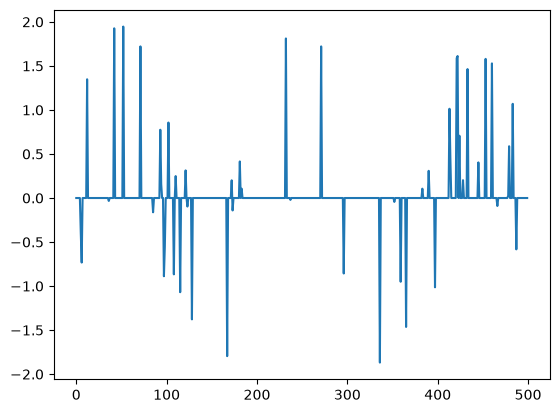

([<matplotlib.lines.Line2D at 0x1dc00bd4690>], None)

In [16]:

XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Redfining the Optimization
Hmmmm. Enen though the optimization has not finished doing its job if we look at the result we seem to have achieved what we asked for!

The reconstructed signal $xrecon$ looks exactly like $xp$. So we did achieve what we wanted (theoritically speaking) but we want more.

What else can we do?

Lets add a condition that we want to optimize $||xrecon - xp ||$ but we also want to keep XX sparse, i.e. the $L0$ norm of $XX$ should be less than $n$.

Iteration limit reached    (Exit mode 9)
            Current function value: 1.9339082806814224e-05
            Iterations: 100
            Function evaluations: 51268
            Gradient evaluations: 101


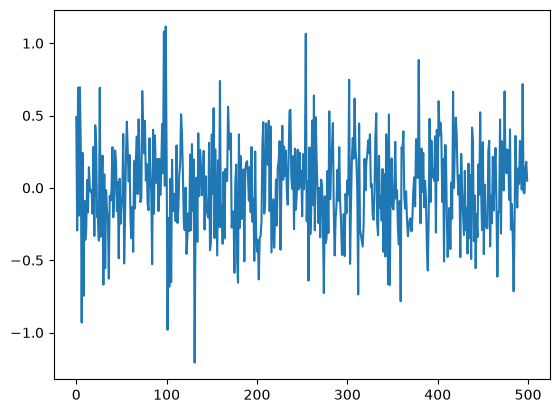

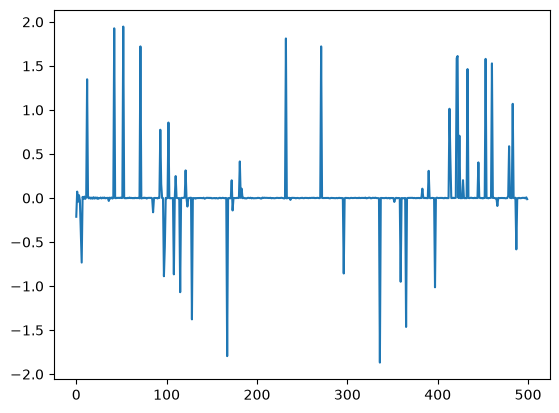

([<matplotlib.lines.Line2D at 0x1dc03f5d1d0>], None)

In [17]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

cons = ({'type': 'ineq',
          'fun' : lambda XX: n - np.linalg.norm(XX,ord=0)})

#seed = np.random.rand(N)
seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Re-redfining the Optimization: L1 Magic!!
Hmmmm. It seems its not working the way we want it to work. What else can we do?

It seems achieving $xrecon = xp$ is an easy task, because its sparse anyway.

So lets keep this as a condition (instead of making it the cost-function). And minimize $XX$. And let us use $L1$ norm here so as to keep the error under control. Remember that even though $L2$ norm is smooth, it has a square and blows up the error. So in wildly uknown problems like what we dealing with here, its better to use $L1$ norm.

In [18]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    return np.linalg.norm(XX, ord=1)

cons = ({'type': 'eq',
          'fun' : lambda XX : np.linalg.norm(xp - fftpack.idct(XX, norm='ortho')*sp, ord = 2)})

seed = np.random.rand(N)
#seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

Iteration limit reached    (Exit mode 9)
            Current function value: 65.28272179843161
            Iterations: 100
            Function evaluations: 50917
            Gradient evaluations: 101


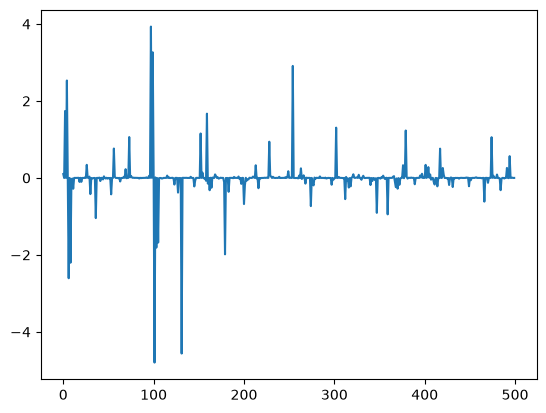

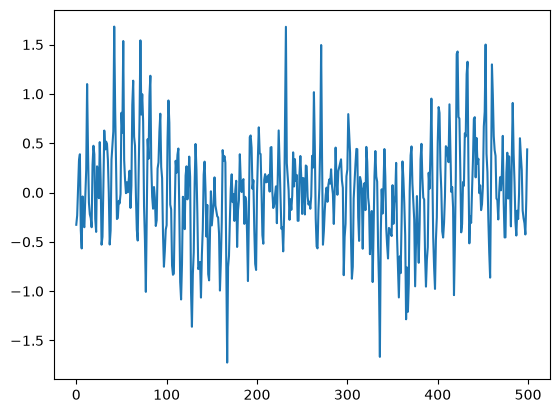

([<matplotlib.lines.Line2D at 0x1dc04031d10>], None)

In [19]:
xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Conclusion
Unfortunately the optimization process did not end. We need more iteration. However, we seem to have got something which looks pretty much like the signal we have started with. It is noisy but it is encouraging given the fact that we have got only half the number of samples as Nyquist would have wanted.

This is the starting of Compressive Sensing (CS). We have learnt two things.

1- It is easy to cheat Nyquist if the signal is sparse in some other linearly transferable domain. 2- Redefining the optimization problem can help us achieve magical results.

The hard-core CS involvs more interesting objective functions and constraints to achieve even more interesting magical results.

In [20]:
import ee
import geemap
import os

ee.Authenticate()

# Wstaw ID swojego projektu Google Cloud
ee.Initialize(project="robust-delight-452915-r1")


Successfully saved authorization token.


### Compressive Sensing — Observations

In Earth Observation, this approach could be useful for reconstructing signals from limited measurements, especially in SAR and hyperspectral imaging. It could also help reduce the amount of data that needs to be collected or transmitted.

In [21]:
# Centrum Krakowa
# Urban area – centrum Krakowa
urban = ee.Geometry.Point(
    [19.9383, 50.0614]
).buffer(1000).bounds()

# Natural area – Puszcza Białowieska
natural = ee.Geometry.Point(
    [23.8331, 52.7425]
).buffer(1000).bounds()

regions = {
    "urban": urban,
    "natural": natural
}
regions = {
    "urban": urban,
    "natural": natural
}

os.makedirs("sentinel_data", exist_ok=True)

In [22]:
def mask_s2(image):
    scl = image.select("SCL")

    clear = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return image.updateMask(clear)


for name, region in regions.items():

    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(region)
        .filterDate("2025-06-01", "2025-09-01")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 15))
        .sort("CLOUDY_PIXEL_PERCENTAGE")
    )

    if collection.size().getInfo() == 0:
        print(f"No Sentinel-2 data: {name}")
        continue

    image = ee.Image(collection.first())

    date = image.date().format("YYYY-MM-dd").getInfo()
    print(f"Sentinel-2 {name}: {date}")

    image = (
        mask_s2(image)
        .select(["B2", "B4", "B8"])
        .divide(10000)
        .clip(region)
        .unmask(-9999)
        .toFloat()
    )

    geemap.ee_export_image(
        image,
        filename=f"sentinel_data/S2_{name}.tif",
        scale=10,
        region=region,
        file_per_band=False
    )

Sentinel-2 urban: 2025-08-13
Generating URL ...
Please wait ...
Data downloaded to m:\Mikolaj\ML4space\lab2\sentinel_data\S2_urban.tif
Sentinel-2 natural: 2025-07-02
Generating URL ...
Please wait ...
Data downloaded to m:\Mikolaj\ML4space\lab2\sentinel_data\S2_natural.tif


In [23]:
for name, region in regions.items():

    collection = (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(region)
        .filterDate("2025-06-01", "2025-09-01")
        .filter(ee.Filter.eq("instrumentMode", "IW"))
        .filter(
            ee.Filter.listContains(
                "transmitterReceiverPolarisation", "VV"
            )
        )
        .filter(
            ee.Filter.listContains(
                "transmitterReceiverPolarisation", "VH"
            )
        )
        .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
        .sort("system:time_start")
    )

    if collection.size().getInfo() == 0:
        print(f"No Sentinel-1 data: {name}")
        continue

    image = ee.Image(collection.first())

    date = image.date().format("YYYY-MM-dd").getInfo()
    print(f"Sentinel-1 {name}: {date}")

    image = (
        image.select(["VV", "VH"])
        .clip(region)
        .unmask(-9999)
        .toFloat()
    )

    geemap.ee_export_image(
        image,
        filename=f"sentinel_data/S1_{name}.tif",
        scale=10,
        region=region,
        file_per_band=False
    )

Sentinel-1 urban: 2025-06-01
Generating URL ...
Please wait ...
Data downloaded to m:\Mikolaj\ML4space\lab2\sentinel_data\S1_urban.tif
Sentinel-1 natural: 2025-06-02
Generating URL ...
Please wait ...
Data downloaded to m:\Mikolaj\ML4space\lab2\sentinel_data\S1_natural.tif


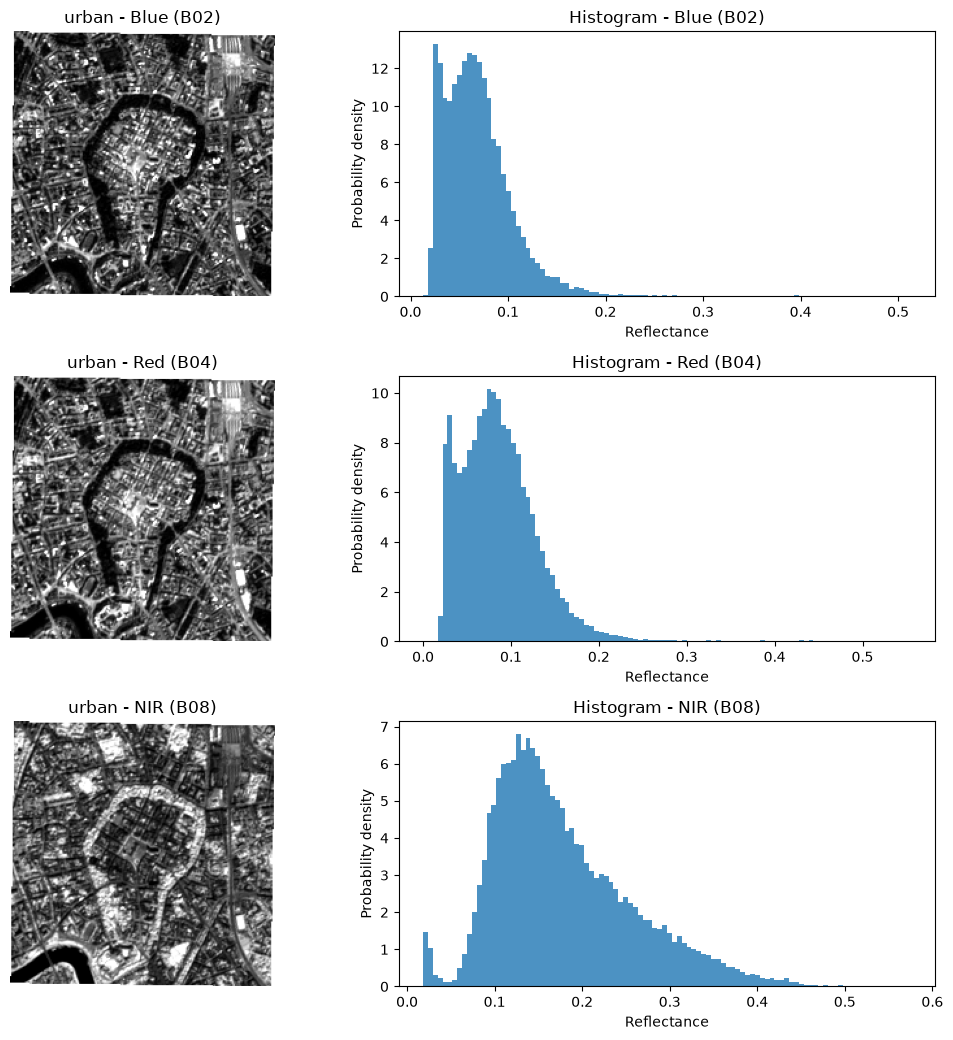

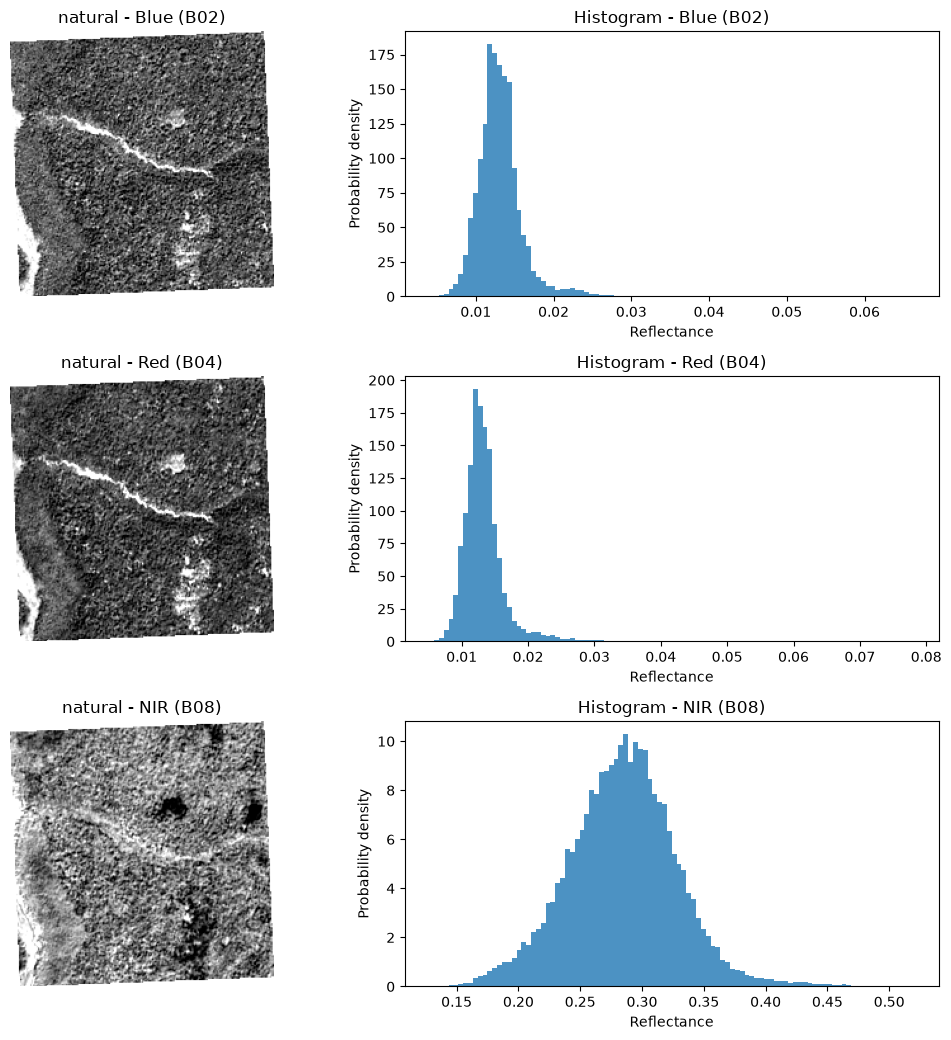

In [25]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt

bands = ["Blue (B02)", "Red (B04)", "NIR (B08)"]

for name in ["urban", "natural"]:

    path = f"sentinel_data/S2_{name}.tif"

    if not os.path.exists(path):
        continue

    with rasterio.open(path) as src:
        data = src.read()

    fig, axes = plt.subplots(
        len(data), 2,
        figsize=(11, 3.5 * len(data))
    )

    for i, band_name in enumerate(bands):

        band = data[i]
        valid = band[(band != -9999) & np.isfinite(band)]

        if len(valid) == 0:
            continue

        vmin, vmax = np.percentile(valid, [2, 98])

        axes[i, 0].imshow(
            np.ma.masked_where(band == -9999, band),
            cmap="gray",
            vmin=vmin,
            vmax=vmax
        )

        axes[i, 0].set_title(f"{name} - {band_name}")
        axes[i, 0].axis("off")

        axes[i, 1].hist(
            valid,
            bins=100,
            density=True,
            alpha=0.8
        )

        axes[i, 1].set_title(f"Histogram - {band_name}")
        axes[i, 1].set_xlabel("Reflectance")
        axes[i, 1].set_ylabel("Probability density")

    plt.tight_layout()
    plt.show()

### Sentinel-2 — Observations

The urban area (Kraków) has a wider range of reflectance values in all three bands, while the forest values are more concentrated.

In the Blue (B02) and Red (B04) bands, the forest has lower reflectance than the city. In the NIR (B08) band, the opposite is visible — the forest has much higher reflectance because of the vegetation.

Overall, the forest has more similar pixel values, while the urban area is more varied due to buildings, roads and other surfaces.

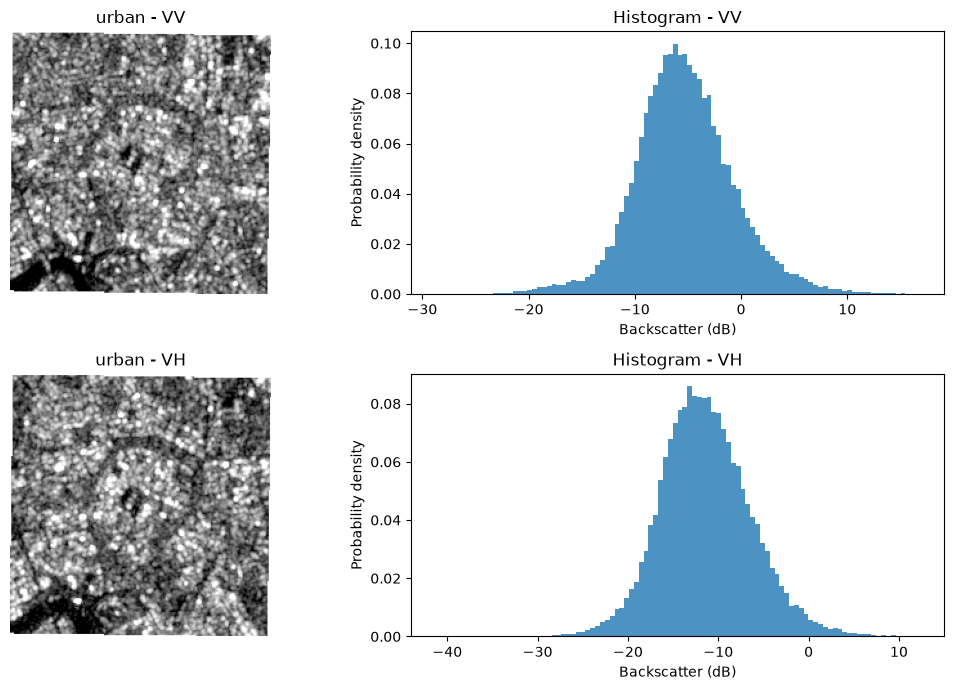

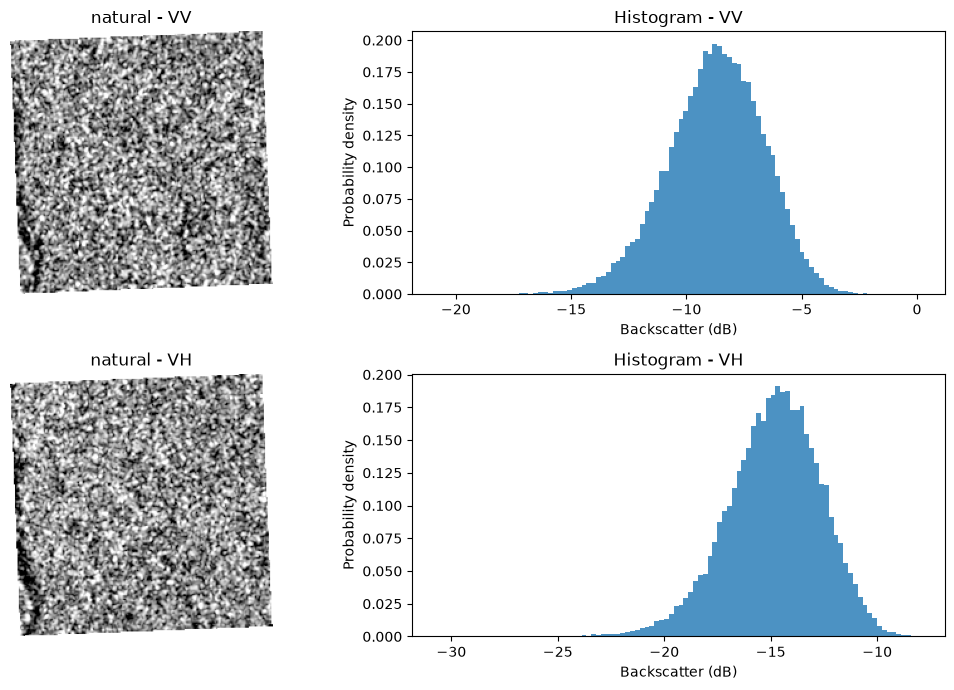

In [28]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt

bands = ["VV", "VH"]

for name in ["urban", "natural"]:

    path = f"sentinel_data/S1_{name}.tif"

    if not os.path.exists(path):
        continue

    with rasterio.open(path) as src:
        data = src.read()

    fig, axes = plt.subplots(
        len(data), 2,
        figsize=(11, 3.5 * len(data))
    )

    for i, band_name in enumerate(bands):

        band = data[i]
        valid = band[(band != -9999) & np.isfinite(band)]

        if len(valid) == 0:
            continue

        vmin, vmax = np.percentile(valid, [2, 98])

        axes[i, 0].imshow(
            np.ma.masked_where(band == -9999, band),
            cmap="gray",
            vmin=vmin,
            vmax=vmax
        )

        axes[i, 0].set_title(f"{name} - {band_name}")
        axes[i, 0].axis("off")

        axes[i, 1].hist(
            valid,
            bins=100,
            density=True,
            alpha=0.8
        )

        axes[i, 1].set_title(f"Histogram - {band_name}")
        axes[i, 1].set_xlabel("Backscatter (dB)")
        axes[i, 1].set_ylabel("Probability density")

    plt.tight_layout()
    plt.show()

### Sentinel-1 — Observations

The urban area (Kraków) has higher backscatter values in both VV and VH polarizations compared to Białowieża Forest.

The histograms for Kraków are wider, with more variation in pixel values, mainly because of buildings and other urban structures.

The forest has a narrower distribution, with most values concentrated around -8.5 dB for VV and -14.5 dB for VH.

Overall, Sentinel-1 shows differences between urban and forest areas based on radar backscatter.

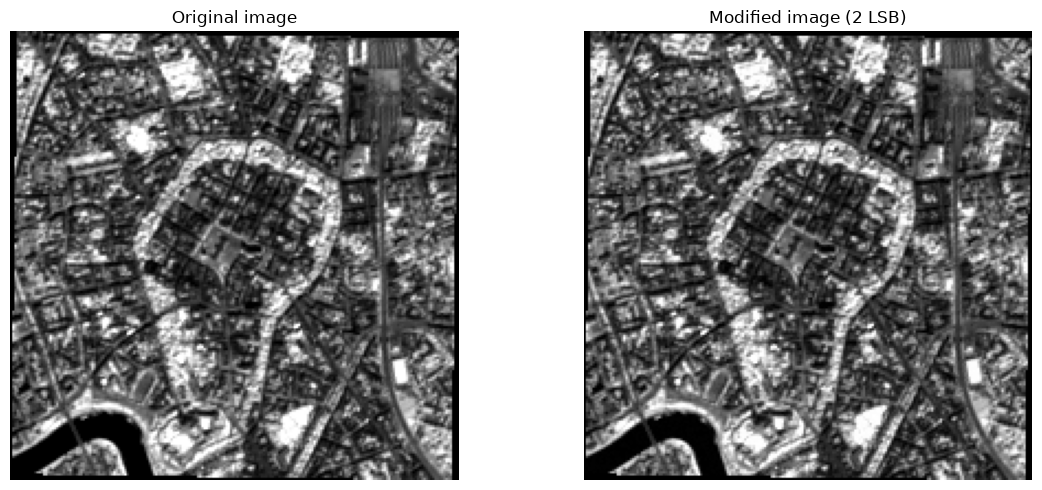

In [30]:

# Load Sentinel-2 NIR band
with rasterio.open("sentinel_data/S2_urban.tif") as src:
    image = src.read(3)

# Convert to 8-bit image
valid = (image != -9999) & np.isfinite(image)

image8 = np.zeros(image.shape, dtype=np.uint8)

vmin, vmax = np.percentile(image[valid], [2, 98])

image8[valid] = (
    np.clip((image[valid] - vmin) / (vmax - vmin), 0, 1) * 255
).astype(np.uint8)

# Replace the last two bits with random values
rng = np.random.default_rng(42)
random_bits = rng.integers(0, 4, image8.shape, dtype=np.uint8)

modified = (image8 & 0b11111100) | random_bits

# Keep NoData pixels unchanged
modified[~valid] = image8[~valid]

# Compare images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image8, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(modified, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Modified image (2 LSB)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Does it affect the visual quality?

There is almost no visible difference between the original and modified images. Changing only the last two bits has a very small effect on pixel brightness.

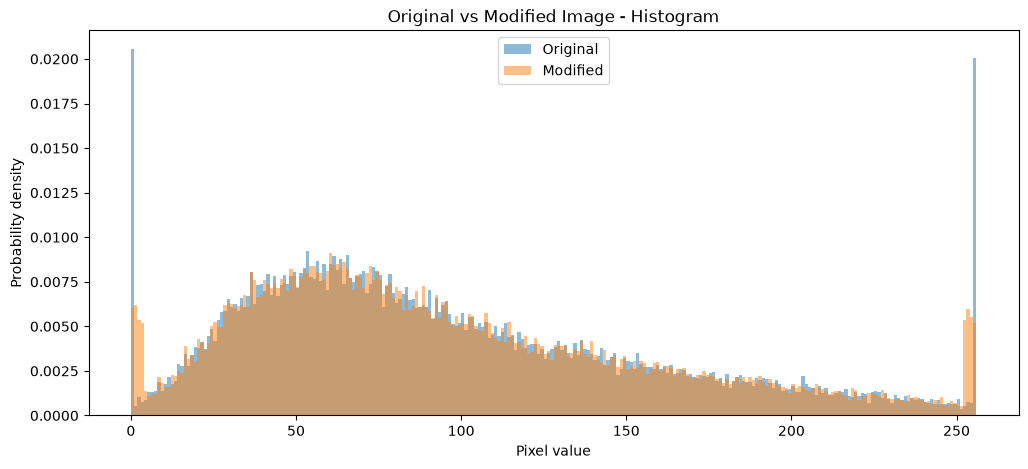

In [31]:
# Compare histograms
plt.figure(figsize=(12, 5))

plt.hist(
    image8[valid],
    bins=256,
    range=(0, 256),
    density=True,
    alpha=0.5,
    label="Original"
)

plt.hist(
    modified[valid],
    bins=256,
    range=(0, 256),
    density=True,
    alpha=0.5,
    label="Modified"
)

plt.xlabel("Pixel value")
plt.ylabel("Probability density")
plt.title("Original vs Modified Image - Histogram")
plt.legend()

plt.show()

### Do you see any difference in the histograms?

The histograms look similar overall, but small differences can be seen in the distribution of pixel values.

In [32]:
difference = np.abs(
    image8.astype(np.int16) - modified.astype(np.int16)
)

print("Maximum difference:", difference[valid].max())
print("Mean difference:", difference[valid].mean())
print(
    "Changed pixels (%):",
    100 * np.mean(image8[valid] != modified[valid])
)

Maximum difference: 3
Mean difference: 1.2592215405251
Changed pixels (%): 74.99441118756054


### Can this be used to detect image manipulation?

Yes, histogram analysis can help detect some changes in an image, even when they are not visible. However, it cannot reliably detect every type of manipulation.